# Phong — Dataset, dựng đồ thị, baseline

Notebook thực hiện các yêu cầu trong `plan/02_PHONG.md` (tổng quan: `plan/00_TONG_QUAN.md`).

| Phần | Nội dung theo kế hoạch | Đầu ra |
|---|---|---|
| 0 | Cấu hình, môi trường | — |
| 1 | **Tuần 1 – Ngày 1:** kiểm tra G1–G3 (IP, timestamp, nhãn), 5 dòng đầu làm bằng chứng | `data/README.md` |
| 2 | **Tuần 1 – Ngày 2:** G4–G6, thống kê, khả năng so sánh, chấm điểm, phiếu dataset | `dataset_cards/*.md` |
| 3 | **Tuần 1 – Ngày 4–5:** làm sạch, chọn đặc trưng, chuẩn hóa, dựng đồ thị, chia theo thời gian | `clean_<bộ>.parquet`, `phong_features.md`, `scaler.pkl`, `graphs_*.pt`, `split.json` |
| 4 | **Tuần 1 – Ngày 6–7:** thống kê đồ thị, kiểm tra rò rỉ, kiểm tra chạy lại cho cùng kết quả | `results/phong_graph_stats.csv` |
| 5 | Tổng kết, hạn chế, việc cần làm tiếp | — |

Phạm vi: **chỉ Tuần 1** (Tuần 2–3 làm ở notebook sau).

Quy ước chung (mục 3 của tổng quan): seed `42`, chia **theo thời gian**, không chồng cửa sổ giữa các tập,
FPR = FP/(FP+TN) với lớp *bình thường* so với *mọi tấn công gộp*, đo hiệu năng warm-up 20 lần + đo 200 lần (trung bình và p95).

## 0. Cấu hình và môi trường

In [1]:
import os, sys, io, json, time, pickle, hashlib, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import torch
import torch_geometric
from torch_geometric.data import Data

import sklearn
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

# Thư mục gốc repo = thư mục chứa plan/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'plan').exists())
DATA, PROC = ROOT / 'data', ROOT / 'data' / 'processed'
RESULTS, CARDS = ROOT / 'results', ROOT / 'dataset_cards'
for d in (PROC, RESULTS, CARDS):
    d.mkdir(parents=True, exist_ok=True)

# Dữ liệu hiện đang để ở data/<bộ>/ (kế hoạch gợi ý data/raw/ — chỉ cần sửa đường dẫn ở đây nếu chuyển)
FILES = {
    'ton_iot':       DATA / 'ToN_IoT' / 'ToN-IoT.csv',
    'nf_ton_iot_v2': DATA / 'ToN_IoT' / 'NF-ToN-IoT-v2.csv',
    'bot_iot':       DATA / 'BoT-IoT' / 'BoT-IoT.csv',
    'nf_bot_iot_v2': DATA / 'BoT-IoT' / 'NF-BoT-IoT-v2.csv',
}

SEED = 42                            # seed chung của nhóm
PIPELINE_DATASET = 'nf_ton_iot_v2'   # bộ dùng để dựng đồ thị (xem lý do ở mục 3.0)
# Cửa sổ theo từng bộ. Bộ có timestamp thật: đơn vị giây. NF-v2 không có timestamp → `ts` = số thứ tự dòng,
# cửa sổ tính bằng số flow liên tiếp (giả định thứ tự dòng là thứ tự thời gian, đã kiểm tra ở mục 2.2).
WINDOW_CFG = {
    'bot_iot':       dict(window=5,    stride=5,    unit='giây'),
    'ton_iot':       dict(window=5,    stride=5,    unit='giây'),
    'nf_ton_iot_v2': dict(window=1000, stride=1000, unit='flow'),
}
WINDOW_SEC = WINDOW_CFG[PIPELINE_DATASET]['window']   # độ dài cửa sổ (giây hoặc số flow)
STRIDE_SEC = WINDOW_CFG[PIPELINE_DATASET]['stride']   # bước trượt; WINDOW_SEC phải chia hết cho STRIDE_SEC
TS_UNIT = WINDOW_CFG[PIPELINE_DATASET]['unit']
SPLIT_RATIO = (0.70, 0.15, 0.15)
# 'chronological': train < val < test trên toàn trục thời gian (đúng quy định trong tổng quan).
# 'blocked': chia trục thời gian thành SPLIT_BLOCKS khối liên tiếp, trong mỗi khối lấy 70/15/15 theo thời gian
#            (chỉ là phương án đề xuất, xem mục 3.4 — cần Phúc duyệt trước khi dùng).
SPLIT_MODE = 'chronological'
SPLIT_BLOCKS = 10
BUILD_CHUNK_WINDOWS = 1000           # dựng đồ thị theo lô cửa sổ để tiết kiệm RAM
TODAY = time.strftime('%Y-%m-%d')

# Màu biểu đồ: 1 chuỗi = 1 màu xanh; ma trận nhầm lẫn = thang xanh 1 sắc độ
BLUE = '#2a78d6'
SEQ_BLUE = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e5e5e5', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'axes.edgecolor': '#999999', 'figure.dpi': 110})

def set_seed(s=SEED):
    import random
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed()
print('ROOT      :', ROOT)
print('Python    :', platform.python_version(), '|', platform.platform())
print('torch     :', torch.__version__, '| PyG:', torch_geometric.__version__,
      '| sklearn:', sklearn.__version__, '| pandas:', pd.__version__, '| numpy:', np.__version__)
for k, p in FILES.items():
    print(f'{k:14s} {p.relative_to(ROOT)}  {p.stat().st_size/2**20:8.1f} MB  exists={p.exists()}')

E:\Program Files\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


E:\Program Files\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


ROOT      : E:\DSS-Project\iot-gat-intrusion-detection
Python    : 3.12.0 | Windows-11-10.0.26200-SP0
torch     : 2.14.1+cpu | PyG: 2.8.1 | sklearn: 1.9.1 | pandas: 3.0.6 | numpy: 2.4.6
ton_iot        data\ToN_IoT\ToN-IoT.csv      28.5 MB  exists=True
nf_ton_iot_v2  data\ToN_IoT\NF-ToN-IoT-v2.csv    2552.5 MB  exists=True
bot_iot        data\BoT-IoT\BoT-IoT.csv     208.2 MB  exists=True
nf_bot_iot_v2  data\BoT-IoT\NF-BoT-IoT-v2.csv    5767.2 MB  exists=True


## 1. Tuần 1 – Ngày 1: kiểm tra G1–G3

- **G1** có IP (hoặc MAC) nguồn/đích; **G2** có timestamp để chia cửa sổ; **G3** có nhãn.
- Cột được dò tự động theo danh sách tên thường gặp của từng bộ. 5 dòng đầu in ra bên dưới là bằng chứng (thay cho ảnh chụp).

In [2]:
IP_CANDIDATES = [('src_ip', 'dst_ip'), ('saddr', 'daddr'), ('IPV4_SRC_ADDR', 'IPV4_DST_ADDR'),
                 ('smac', 'dmac')]
TS_CANDIDATES = ['ts', 'stime', 'FLOW_START_MILLISECONDS', 'timestamp', 'Timestamp']
LABEL_CANDIDATES = ['type', 'category', 'Attack', 'attack_cat', 'label', 'Label', 'attack']

BIG_FILE = 1 * 2**30     # file > 1 GB: đọc bằng pyarrow, chỉ lấy các cột cần

def read_any(path, columns=None):
    if path.stat().st_size > BIG_FILE:
        opts = pacsv.ConvertOptions(include_columns=columns) if columns else None
        return pacsv.read_csv(path, convert_options=opts).to_pandas()
    df = pd.read_csv(path, low_memory=False, encoding='utf-8-sig')
    df.columns = df.columns.str.strip()
    return df if columns is None else df[columns]

def schema_of(path):
    return list(pd.read_csv(path, nrows=0, encoding='utf-8-sig').columns.str.strip())

def head5(path):
    return pd.read_csv(path, nrows=5, encoding='utf-8-sig').rename(columns=str.strip)

def detect(cols):
    ip = next((p for p in IP_CANDIDATES if p[0] in cols and p[1] in cols), None)
    # cột MAC trong BoT-IoT tồn tại nhưng rỗng → chỉ coi là IP nếu là cặp IP
    ts = next((c for c in TS_CANDIDATES if c in cols), None)
    labels = [c for c in LABEL_CANDIDATES if c in cols]
    return ip, ts, labels

G123 = {}
for name, path in FILES.items():
    cols = schema_of(path)
    ip, ts, labels = detect(cols)
    G123[name] = dict(n_cols=len(cols), ip=ip, ts=ts, labels=labels,
                      G1=ip is not None and ip[0] != 'smac', G2=ts is not None, G3=len(labels) > 0)
    print(f'\n=== {name}  ({len(cols)} cột) ===')
    print(f'G1 IP nguồn/đích : {ip}   G2 timestamp: {ts}   G3 nhãn: {labels}')
    h = head5(path)
    show = [c for c in ([*(ip or ()), ts, *labels]) if c] or list(h.columns[:8])
    display(h[show] if set(show) <= set(h.columns) else h.iloc[:, :10])

g123_df = pd.DataFrame(G123).T[['n_cols', 'ip', 'ts', 'labels', 'G1', 'G2', 'G3']]
g123_df


=== ton_iot  (44 cột) ===
G1 IP nguồn/đích : ('src_ip', 'dst_ip')   G2 timestamp: None   G3 nhãn: ['type', 'label']


,src_ip,dst_ip,type,label
0,192.168.1.37,192.168.1.193,backdoor,1
1,192.168.1.193,192.168.1.37,backdoor,1
2,192.168.1.193,192.168.1.37,backdoor,1
3,192.168.1.193,192.168.1.37,backdoor,1
4,192.168.1.193,192.168.1.37,backdoor,1



=== nf_ton_iot_v2  (45 cột) ===
G1 IP nguồn/đích : ('IPV4_SRC_ADDR', 'IPV4_DST_ADDR')   G2 timestamp: None   G3 nhãn: ['Attack', 'Label']


,IPV4_SRC_ADDR,IPV4_DST_ADDR,Attack,Label
0,192.168.1.193,192.168.1.33,ransomware,1
1,192.168.1.193,192.168.1.152,Benign,0
2,192.168.1.152,192.168.1.193,Benign,0
3,192.168.1.169,239.255.255.250,Benign,0
4,192.168.1.79,192.168.1.255,Benign,0



=== bot_iot  (35 cột) ===
G1 IP nguồn/đích : ('saddr', 'daddr')   G2 timestamp: stime   G3 nhãn: ['category', 'attack']


,saddr,daddr,stime,category,attack
0,192.168.100.1,192.168.100.3,1.526344e+09,Normal,0
1,192.168.100.7,192.168.100.4,1.526344e+09,Normal,0
2,192.168.100.149,27.124.125.250,1.526344e+09,Normal,0
3,192.168.100.4,192.168.100.7,1.526344e+09,Normal,0
4,192.168.100.27,192.168.100.1,1.526344e+09,Normal,0



=== nf_bot_iot_v2  (45 cột) ===
G1 IP nguồn/đích : ('IPV4_SRC_ADDR', 'IPV4_DST_ADDR')   G2 timestamp: None   G3 nhãn: ['Attack', 'Label']


,IPV4_SRC_ADDR,IPV4_DST_ADDR,Attack,Label
0,192.168.100.149,192.168.100.6,DoS,1
1,192.168.100.147,192.168.100.5,DoS,1
2,192.168.100.148,192.168.100.5,DoS,1
3,192.168.100.147,192.168.100.7,DDoS,1
4,192.168.100.150,192.168.100.6,DDoS,1


,n_cols,ip,ts,labels,G1,G2,G3
ton_iot,44,"(src_ip, dst_ip)",None,"[type, label]",True,False,True
nf_ton_iot_v2,45,"(IPV4_SRC_ADDR, IPV4_DST_ADDR)",None,"[Attack, Label]",True,False,True
bot_iot,35,"(saddr, daddr)",stime,"[category, attack]",True,True,True
nf_bot_iot_v2,45,"(IPV4_SRC_ADDR, IPV4_DST_ADDR)",None,"[Attack, Label]",True,False,True


**Nhận xét Ngày 1 (dựa trên file đang có trong `data/`):**

- `ToN-IoT.csv` có IP + nhãn, **không có cột `ts`** → chưa đạt G2. Đây là bản rút gọn (211.043 dòng, các lớp nằm thành khối liên tiếp), không phải `Processed_Network_dataset` gốc (bản gốc có cột `ts`).
- `NF-ToN-IoT-v2.csv` và `NF-BoT-IoT-v2.csv` (bản CSV đầy đủ): **có `IPV4_SRC_ADDR`/`IPV4_DST_ADDR`** → đạt G1. Họ NetFlow-v2 **không có cột timestamp** → trượt G2 theo nghĩa chặt. Mục 2.2 kiểm tra thứ tự dòng có dùng thay thời gian được không.
- `BoT-IoT.csv` có IP (`saddr`, `daddr`), timestamp (`stime`) và nhãn → đạt G1–G3. Cần xem tiếp G4 ở Ngày 2.

In [3]:
readme = f"""# Dữ liệu (không commit dữ liệu gốc)

Cập nhật: {TODAY} — Phong

| Bộ | File hiện có | Link chính thức | Ghi chú |
|---|---|---|---|
| ToN-IoT (network) | `data/ToN_IoT/ToN-IoT.csv` | https://research.unsw.edu.au/projects/toniot-datasets | Bản rút gọn, thiếu cột `ts`; cần tải `Processed_datasets/Processed_Network_dataset` |
| NF-ToN-IoT-v2 | `data/ToN_IoT/NF-ToN-IoT-v2.csv` | https://staff.itee.uq.edu.au/marius/NIDS_datasets/ | Bản CSV đầy đủ (2,5 GB), có IP; không có timestamp, thứ tự dòng theo thời gian (giả định) |
| BoT-IoT | `data/BoT-IoT/BoT-IoT.csv` | https://research.unsw.edu.au/projects/bot-iot-dataset | 1.000.000 dòng, chỉ có Normal + Reconnaissance (chính là `data_1.csv` của bộ đầy đủ) |
| BoT-IoT (đầy đủ) | `data/BoT-IoT/kaggle_full/data_1..74.csv` | Kaggle `vigneshvenkateswaran/bot-iot` | 74 file, 14 GB, ~73 triệu flow, có timestamp `stime`; tải bằng `kagglehub` (không cần tài khoản), xử lý trong `notebooks/phong_tuan1_bot_iot_full.ipynb` |
| NF-BoT-IoT-v2 | `data/BoT-IoT/NF-BoT-IoT-v2.csv` | https://staff.itee.uq.edu.au/marius/NIDS_datasets/ | Bản CSV đầy đủ (5,6 GB), có IP; không có timestamp và các dòng đã bị xáo trộn |

Nguồn tải cụ thể của 4 file hiện có (Kaggle/trang gốc): **Phong bổ sung**.

`data/processed/` do `notebooks/phong_tuan1_dataset_graph.ipynb` sinh ra: `clean_<bộ>.parquet`, `graphs_<bộ>_w*s*.pt`, `split.json`, `scaler.pkl`.
`data/processed/bot_iot_full/` do `notebooks/phong_tuan1_bot_iot_full.ipynb` sinh ra (bộ file riêng: clean, vocab, graphs, split, scaler).
"""
(DATA / 'README.md').write_text(readme, encoding='utf-8')
print('Đã ghi', (DATA / 'README.md').relative_to(ROOT))

Đã ghi data\README.md


## 2. Tuần 1 – Ngày 2: khảo sát sâu (G4–G6, thống kê, chấm điểm)

### 2.1 Ánh xạ nhãn gốc → nhóm dùng chung
Nhóm theo G4: **DoS_DDoS**, **Botnet_Backdoor** (botnet, backdoor, C&C), **Truy_cap_trai_phep** (scanning/recon, brute force/password, injection, XSS, theft), **Khac** (mitm, ransomware…), **Normal**.

In [4]:
GROUP_ORDER = ['Normal', 'DoS_DDoS', 'Botnet_Backdoor', 'Truy_cap_trai_phep', 'Khac']
GROUP_MAP = {
    'normal': 'Normal', 'benign': 'Normal',
    'ddos': 'DoS_DDoS', 'dos': 'DoS_DDoS',
    'backdoor': 'Botnet_Backdoor', 'botnet': 'Botnet_Backdoor', 'bot': 'Botnet_Backdoor',
    'scanning': 'Truy_cap_trai_phep', 'reconnaissance': 'Truy_cap_trai_phep',
    'password': 'Truy_cap_trai_phep', 'injection': 'Truy_cap_trai_phep',
    'xss': 'Truy_cap_trai_phep', 'theft': 'Truy_cap_trai_phep',
    'mitm': 'Khac', 'ransomware': 'Khac',
}
def to_group(raw):
    return pd.Series(raw).astype(str).str.strip().str.lower().map(GROUP_MAP).fillna('Khac').values

LABEL_COL = {'ton_iot': 'type', 'bot_iot': 'category', 'nf_ton_iot_v2': 'Attack', 'nf_bot_iot_v2': 'Attack'}

### 2.2 Đọc thử (G6), thống kê IP, số mẫu từng lớp

In [5]:
SURVEY, LABEL_TABLES = {}, {}
for name, path in FILES.items():
    info = G123[name]
    lab = LABEL_COL[name]
    t0 = time.perf_counter()
    if path.stat().st_size > BIG_FILE:
        df = read_any(path, columns=[*info['ip'], lab])
        read_note = f'đọc 3 cột (IP nguồn, IP đích, nhãn) bằng pyarrow {time.perf_counter() - t0:.1f}s'
    else:
        df = read_any(path)
        read_note = f'đọc toàn bộ CSV {time.perf_counter() - t0:.1f}s'
    n_rows = len(df)
    vc = df[lab].astype(str).str.strip().value_counts()
    tab = vc.rename('so_mau').to_frame()
    tab['ti_le_%'] = (tab.so_mau / n_rows * 100).round(3)
    tab['nhom'] = to_group(tab.index)
    LABEL_TABLES[name] = tab
    grp = tab.groupby('nhom').so_mau.sum()
    s = dict(rows=n_rows, size_mb=round(path.stat().st_size / 2**20, 1), read_note=read_note,
             n_classes=len(vc), normal_pct=round(grp.get('Normal', 0) / n_rows * 100, 2),
             smallest=f'{vc.index[-1]} ({vc.iloc[-1] / n_rows * 100:.3f}%)',
             groups_attack=[g for g in GROUP_ORDER[1:4] if grp.get(g, 0) > 0])
    s['G4'] = len(s['groups_attack']) == 3
    if info['ip'] and info['ip'][0] in df.columns:
        s['n_src_ip'], s['n_dst_ip'] = df[info['ip'][0]].nunique(), df[info['ip'][1]].nunique()
        s['n_ip_total'] = pd.unique(pd.concat([df[info['ip'][0]], df[info['ip'][1]]]).dropna()).size
    else:
        s['n_src_ip'] = s['n_dst_ip'] = s['n_ip_total'] = None
    if name == 'bot_iot':
        s['sub'] = df.groupby(['category', 'subcategory']).size()
        s['time_range'] = (pd.to_datetime(df.stime.min(), unit='s'), pd.to_datetime(df.stime.max(), unit='s'))
        s['attacker_ips'] = df[df.category != 'Normal'].saddr.value_counts().head(8)
    # Thứ tự dòng: nếu dữ liệu bị xáo trộn, mỗi khối 100.000 dòng có thành phần nhãn ≈ toàn bộ file
    # (tỉ lệ lớp trội ≈ tỉ lệ lớp lớn nhất). Nếu xếp theo thời gian, nhãn đi thành từng pha dài.
    lv = df[lab].astype(str).to_numpy()
    s['mean_label_run'] = round(n_rows / ((lv[1:] != lv[:-1]).sum() + 1), 1)
    chunk = pd.Series(lv).groupby(np.arange(n_rows) // 100_000)
    s['chunk_purity'] = round(chunk.agg(lambda x: x.value_counts(normalize=True).iloc[0]).median(), 3)
    s['global_top_share'] = round(vc.iloc[0] / n_rows, 3)
    s['row_order'] = ('xáo trộn' if s['mean_label_run'] < 3 and abs(s['chunk_purity'] - s['global_top_share']) < 0.05
                      else 'theo pha (có thể theo thời gian)')
    if name == 'ton_iot':
        s['dup_rows'] = int(df.duplicated().sum())
    if name == 'nf_ton_iot_v2':
        s['phases'] = chunk.agg(lambda x: x.value_counts().index[0])          # lớp trội của từng khối 100k dòng
    SURVEY[name] = s
    del df, lv

survey_df = pd.DataFrame({k: {c: v for c, v in s.items() if c not in ('sub', 'attacker_ips', 'time_range', 'phases')}
                          for k, s in SURVEY.items()}).T
survey_df

,rows,size_mb,read_note,n_classes,normal_pct,smallest,groups_attack,G4,n_src_ip,n_dst_ip,n_ip_total,mean_label_run,chunk_purity,global_top_share,row_order,dup_rows
ton_iot,211043,28.5,đọc toàn bộ CSV 1.0s,10,23.69,mitm (0.494%),"[DoS_DDoS, Botnet_Backdoor, Truy_cap_trai_phep]",True,51,753,776,21104.3,0.31,0.237,theo pha (có thể theo thời gian),20569
nf_ton_iot_v2,16940496,2552.5,"đọc 3 cột (IP nguồn, IP đích, nhãn) bằng pyarr...",10,36.01,ransomware (0.020%),"[DoS_DDoS, Botnet_Backdoor, Truy_cap_trai_phep]",True,23079,6868,29245,11.3,0.906,0.36,theo pha (có thể theo thời gian),NaN
bot_iot,1000000,208.2,đọc toàn bộ CSV 3.5s,2,0.2,Normal (0.199%),[Truy_cap_trai_phep],False,21,172,180,431.8,0.999,0.998,theo pha (có thể theo thời gian),NaN
nf_bot_iot_v2,37763497,5767.2,"đọc 3 cột (IP nguồn, IP đích, nhãn) bằng pyarr...",5,0.36,Theft (0.006%),"[DoS_DDoS, Truy_cap_trai_phep]",False,20,291,293,1.8,0.485,0.485,xáo trộn,NaN


In [6]:
for name, tab in LABEL_TABLES.items():
    print(f'\n=== {name} ===')
    display(tab)
print('BoT-IoT category/subcategory:'); display(SURVEY['bot_iot']['sub'].rename('so_mau').to_frame())
print('BoT-IoT khoảng thời gian:', SURVEY['bot_iot']['time_range'])
print('BoT-IoT IP nguồn của flow tấn công:'); display(SURVEY['bot_iot']['attacker_ips'].to_frame())
print('ToN-IoT (bản rút gọn): dòng trùng lặp =', SURVEY['ton_iot']['dup_rows'])
ph = SURVEY['nf_ton_iot_v2']['phases']
seq = ph[ph != ph.shift()]
print(f'NF-ToN-IoT-v2: chuỗi pha (lớp trội của các khối 100.000 dòng liên tiếp, {len(ph)} khối):')
print('  ' + ' → '.join(f'{v}@{k}' for k, v in seq.items()))


=== ton_iot ===


,so_mau,ti_le_%,nhom
type,,,
normal,50000,23.692,Normal
backdoor,20000,9.477,Botnet_Backdoor
ddos,20000,9.477,DoS_DDoS
dos,20000,9.477,DoS_DDoS
injection,20000,9.477,Truy_cap_trai_phep
password,20000,9.477,Truy_cap_trai_phep
ransomware,20000,9.477,Khac
scanning,20000,9.477,Truy_cap_trai_phep
xss,20000,9.477,Truy_cap_trai_phep



=== nf_ton_iot_v2 ===


,so_mau,ti_le_%,nhom
Attack,,,
Benign,6099469,36.005,Normal
scanning,3781419,22.322,Truy_cap_trai_phep
xss,2455020,14.492,Truy_cap_trai_phep
ddos,2026234,11.961,DoS_DDoS
password,1153323,6.808,Truy_cap_trai_phep
dos,712609,4.207,DoS_DDoS
injection,684465,4.040,Truy_cap_trai_phep
backdoor,16809,0.099,Botnet_Backdoor
mitm,7723,0.046,Khac



=== bot_iot ===


,so_mau,ti_le_%,nhom
category,,,
Reconnaissance,998007,99.801,Truy_cap_trai_phep
Normal,1993,0.199,Normal


... (3 outputs left out)

,,so_mau
category,subcategory,
Normal,Normal,1993
Reconnaissance,Service_Scan,998007


BoT-IoT khoảng thời gian: (Timestamp('2018-05-15 00:27:11.665139914'), Timestamp('2018-05-22 00:34:12.645503044'))
BoT-IoT IP nguồn của flow tấn công:


,count
saddr,
192.168.100.147,262479
192.168.100.148,250416
192.168.100.149,230021
192.168.100.150,226055
192.168.100.3,16703
192.168.100.5,5073
192.168.100.7,3634
192.168.100.6,3626


ToN-IoT (bản rút gọn): dòng trùng lặp = 20569
NF-ToN-IoT-v2: chuỗi pha (lớp trội của các khối 100.000 dòng liên tiếp, 170 khối):
  Benign@0 → scanning@1 → Benign@5 → scanning@19 → Benign@23 → scanning@26 → Benign@38 → scanning@44 → Benign@46 → scanning@50 → Benign@52 → scanning@63 → Benign@66 → scanning@71 → Benign@76 → scanning@78 → Benign@80 → scanning@83 → Benign@85 → scanning@89 → ddos@90 → scanning@92 → xss@93 → ddos@94 → xss@95 → ddos@120 → xss@121 → ddos@122 → password@131 → ddos@132 → injection@146 → ddos@148 → injection@149 → xss@150 → injection@151 → Benign@153 → password@154 → ddos@159 → password@160 → Benign@162 → password@164 → dos@166 → Benign@169


**Nhận xét thứ tự dòng (quan trọng cho G2):**

- **NF-ToN-IoT-v2:** nhãn đi thành các pha dài và rõ (Benign → scanning → … → xss → ddos → injection → password → dos/backdoor/ransomware ở cuối). Thứ tự này khớp với kịch bản tấn công theo từng đợt của testbed ToN-IoT, nên **thứ tự dòng nhiều khả năng là thứ tự thời gian**. Có thể dùng số thứ tự dòng thay timestamp (cửa sổ = N flow liên tiếp). Đây là **giả định**, cần nêu rõ trong báo cáo.
- **NF-BoT-IoT-v2:** mỗi khối 100.000 dòng có thành phần nhãn gần như giống toàn bộ file → **các dòng đã bị xáo trộn**, không dựng được cửa sổ thời gian.

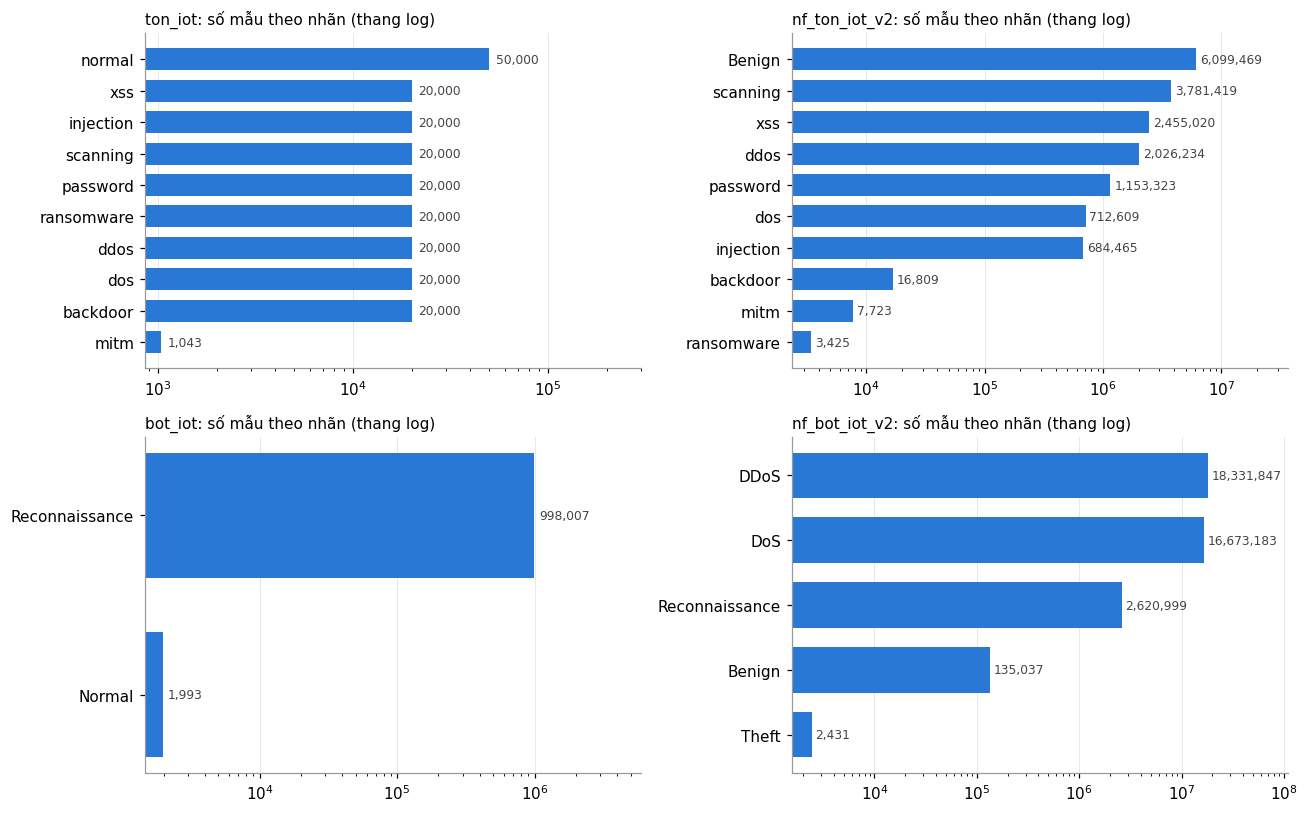

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (name, tab) in zip(axes.ravel(), LABEL_TABLES.items()):
    t = tab.sort_values('so_mau')
    ax.barh(t.index, t.so_mau, color=BLUE, height=0.7)
    ax.set_xscale('log'); ax.grid(axis='y', visible=False)
    ax.set_title(f'{name}: số mẫu theo nhãn (thang log)', fontsize=10, loc='left')
    for y, v in enumerate(t.so_mau):
        ax.text(v * 1.08, y, f'{v:,}', va='center', fontsize=8, color='#444444')
    ax.set_xlim(right=t.so_mau.max() * 6)
fig.tight_layout()
fig.savefig(RESULTS / f'phong_label_distribution_{TODAY}.png', bbox_inches='tight')
plt.show()

### 2.3 G5 (license) và khả năng so sánh / độ khó (tra cứu)

> Các thông tin dưới đây là **hiểu biết ban đầu từ tài liệu**, kế hoạch yêu cầu **kiểm tra lại trên trang gốc và bài báo gốc** trước khi đưa vào báo cáo (cột "Cần xác minh").

| Bộ | License / điều kiện | Bài báo gốc | Một số bài GNN/IDS dùng bộ này | Mức kết quả thường gặp |
|---|---|---|---|---|
| ToN-IoT | Miễn phí cho nghiên cứu học thuật, bắt buộc trích dẫn (UNSW Canberra) | Moustafa (2021), *A new distributed architecture for evaluating AI-based security systems at the edge: ToN_IoT datasets*, Sustainable Cities and Society; Booij et al. (2021) IEEE IoT Journal | E-GraphSAGE (Lo et al., NOMS 2022, bản NF); E-ResGAT (Chang & Branco, 2021); Anomal-E (Caville et al., KBS 2022, bản NF-v2) | Binary ≈ 99%+; multi-class thấp hơn rõ (F1 macro dao động lớn giữa các bài) — cần xác minh |
| NF-ToN-IoT-v2 | Như trên (UQ, trích dẫn Sarhan et al.) | Sarhan, Layeghy, Portmann (2022), *Towards a standard feature set for network intrusion detection system datasets*, MONET | E-GraphSAGE, Anomal-E, E-ResGAT | Binary ≈ 99%+ — cần xác minh |
| BoT-IoT | Miễn phí cho nghiên cứu học thuật, bắt buộc trích dẫn (UNSW Canberra) | Koroniotis et al. (2019), *Towards the development of realistic botnet dataset in the Internet of Things*, FGCS | E-GraphSAGE (bản NF), E-ResGAT, nhiều bài IDS không dùng đồ thị | ≈ 99,9% (rất dễ) — cần xác minh |
| NF-BoT-IoT-v2 | Như NF-ToN-IoT-v2 | Sarhan et al. (2022) | E-GraphSAGE, E-ResGAT | ≈ 99,9% — cần xác minh |

### 2.4 Chấm điểm 7 tiêu chí và tổng hợp

In [8]:
CRITERIA = [('graph', 'Khả năng dựng đồ thị', 30), ('coverage', 'Độ phủ tấn công', 20),
            ('iot', 'Tính IoT thực tế', 15), ('balance', 'Cân bằng lớp', 10),
            ('cost', 'Chi phí xử lý', 10), ('compare', 'Khả năng so sánh', 10), ('difficulty', 'Độ khó hợp lý', 5)]

S = SURVEY
SCORES = {
    'ton_iot': {
        'graph': (25, f"{S['ton_iot']['n_src_ip']} IP nguồn, {S['ton_iot']['n_dst_ip']} IP đích (bản rút gọn); nhiều nạn nhân cho mỗi nguồn tấn công"),
        'coverage': (18, 'Đủ 3 nhóm: ddos/dos; backdoor; scanning/password/injection/xss, mỗi nhóm ≥ 20.000 mẫu. Botnet chỉ có backdoor, không có C&C riêng'),
        'iot': (11, 'Testbed IoT/IIoT gồm thiết bị thật và mô phỏng (hỗn hợp)'),
        'balance': (7, f"Normal {S['ton_iot']['normal_pct']}%; lớp nhỏ nhất {S['ton_iot']['smallest']} < 0,5%"),
        'cost': (8, 'CSV sẵn, bản rút gọn 29 MB; bản Processed_Network_dataset có ts lớn hơn nhiều (cần kiểm tra dung lượng)'),
        'compare': (9, 'Nhiều bài GNN/IDS (chủ yếu bản NF)'),
        'difficulty': (3, 'Binary ≈ 99%+; multi-class khó hơn'),
    },
    'nf_ton_iot_v2': {
        'graph': (22, f"{S['nf_ton_iot_v2']['n_src_ip']:,} IP nguồn, {S['nf_ton_iot_v2']['n_dst_ip']:,} IP đích; không có timestamp, phải dùng thứ tự dòng làm thời gian (giả định)"),
        'coverage': (20, 'Đủ 3 nhóm, số mẫu rất lớn (scanning 3,8M; ddos 2,0M; backdoor 16,8K)'),
        'iot': (11, 'Cùng testbed ToN-IoT (hỗn hợp)'),
        'balance': (4, f"Benign {S['nf_ton_iot_v2']['normal_pct']}%; lớp nhỏ nhất {S['nf_ton_iot_v2']['smallest']}"),
        'cost': (8, f"CSV có sẵn {S['nf_ton_iot_v2']['size_mb']:,} MB (< 5 GB), {S['nf_ton_iot_v2']['rows']:,} dòng"),
        'compare': (10, 'Bộ chuẩn của E-GraphSAGE, Anomal-E, E-ResGAT'),
        'difficulty': (3, 'Binary ≈ 99%+'),
    },
    'bot_iot': {
        'graph': (10, f"{S['bot_iot']['n_src_ip']} IP nguồn, {S['bot_iot']['n_dst_ip']} IP đích; tấn công chỉ đến từ 4 IP (.147–.150)"),
        'coverage': (10, 'File hiện có chỉ có Reconnaissance; bản đầy đủ có DDoS/DoS/Recon/Theft nhưng Theft rất ít, không có C&C riêng'),
        'iot': (8, 'Thiết bị IoT mô phỏng (Node-RED) trên máy ảo'),
        'balance': (2, f"Normal chỉ {S['bot_iot']['normal_pct']}%"),
        'cost': (6, 'File hiện có 208 MB CSV; bản đầy đủ > 16 GB, phải lấy bản 5%'),
        'compare': (9, 'Rất phổ biến trong IDS, có bản NF cho GNN'),
        'difficulty': (1, 'Mô hình đơn giản đã ≈ 99,9%'),
    },
    'nf_bot_iot_v2': {
        'graph': (6, f"Chỉ {S['nf_bot_iot_v2']['n_src_ip']} IP nguồn, {S['nf_bot_iot_v2']['n_dst_ip']} IP đích; không có timestamp và dòng đã bị xáo trộn → không dựng được cửa sổ"),
        'coverage': (12, 'DDoS/DoS và Recon rất nhiều, Theft 2.431; không có botnet/C&C riêng'),
        'iot': (8, 'Cùng testbed BoT-IoT (mô phỏng)'),
        'balance': (2, f"Benign {S['nf_bot_iot_v2']['normal_pct']}%"),
        'cost': (4, f"CSV {S['nf_bot_iot_v2']['size_mb']:,} MB (> 5 GB), {S['nf_bot_iot_v2']['rows']:,} dòng"),
        'compare': (9, 'E-GraphSAGE, E-ResGAT'),
        'difficulty': (1, '≈ 99,9%'),
    },
}
G5 = {k: True for k in FILES}   # học thuật + trích dẫn (cần xác minh trang license)
G6 = {k: True for k in FILES}   # tất cả đọc được trên laptop trong vài giây–vài phút (xem read_note)

rows = []
for name in FILES:
    total = sum(v[0] for v in SCORES[name].values())
    g = {**{f'G{i}': G123[name][f'G{i}'] for i in (1, 2, 3)}, 'G4': SURVEY[name]['G4'], 'G5': G5[name], 'G6': G6[name]}
    rows.append({'dataset': name, **g, 'qua_G1_G6': all(g.values()),
                 **{c[1]: SCORES[name][c[0]][0] for c in CRITERIA}, 'Tong': total})
score_df = pd.DataFrame(rows).set_index('dataset')
score_df

,G1,G2,G3,G4,G5,G6,qua_G1_G6,Khả năng dựng đồ thị,Độ phủ tấn công,Tính IoT thực tế,Cân bằng lớp,Chi phí xử lý,Khả năng so sánh,Độ khó hợp lý,Tong
dataset,,,,,,,,,,,,,,,
ton_iot,True,False,True,True,True,True,False,25,18,11,7,8,9,3,81
nf_ton_iot_v2,True,False,True,True,True,True,False,22,20,11,4,8,10,3,78
bot_iot,True,True,True,False,True,True,False,10,10,8,2,6,9,1,46
nf_bot_iot_v2,True,False,True,False,True,True,False,6,12,8,2,4,9,1,42


**Kết luận khảo sát (để trình bày ở buổi họp Ngày 3, Phúc quyết định):**

1. **Không file nào qua đủ G1–G6 theo nghĩa chặt:**
   - ToN-IoT trượt G2 vì bản đã tải thiếu `ts`.
   - BoT-IoT trượt G4 vì bản đã tải chỉ có Recon.
   - Hai bản NF-v2 trượt G2 vì không có timestamp.
2. **NF-ToN-IoT-v2 (78/100, ≥ 70) là bộ dùng được ngay:** có IP, đủ 3 nhóm tấn công, CSV < 5 GB, thứ tự dòng theo pha thời gian. Đây cũng là phương án dự phòng mà tổng quan (mục 9) đã nêu → **đề xuất làm dataset chính** với giả định "thứ tự dòng = thời gian".
3. **ToN-IoT bản `Processed_Network_dataset` (có `ts`)** về lý thuyết tốt hơn (81 điểm, có timestamp thật) nhưng chưa tải. Đề xuất tải về để kiểm tra lại giả định ở điểm 2, và dùng làm dataset phụ.
4. **Loại NF-BoT-IoT-v2 và BoT-IoT:** dòng bị xáo trộn hoặc chỉ có 1 nhóm tấn công, Normal < 0,5%, quá dễ, ít IP.
5. Mục 3–4 dựng đồ thị trên `PIPELINE_DATASET = 'nf_ton_iot_v2'`. Muốn chạy bộ khác thì đổi biến này (`'bot_iot'`, hoặc `'ton_iot'` khi có file có `ts`).

### 2.5 Ghi phiếu dataset (`dataset_cards/*.md`, theo Phụ lục A)

In [9]:
CARD_META = {
    'ton_iot': ('ToN-IoT (network)', 'https://research.unsw.edu.au/projects/toniot-datasets', 'Học thuật, bắt buộc trích dẫn (UNSW)', 'Moustafa (2021), Sustainable Cities and Society',
                'Làm dataset phụ — cần tải bản `Processed_Network_dataset` (có `ts`) để kiểm chứng giả định thứ tự dòng của NF-ToN-IoT-v2',
                'Bản đang có thiếu `ts` (trượt G2) và xếp theo lớp; bản đầy đủ lớn hơn nhiều; mitm < 0,5%.'),
    'nf_ton_iot_v2': ('NF-ToN-IoT-v2', 'https://staff.itee.uq.edu.au/marius/NIDS_datasets/', 'Học thuật, trích dẫn Sarhan et al.', 'Sarhan et al. (2022), MONET',
                      'Có — đề xuất làm dataset chính (dùng thứ tự dòng thay timestamp)',
                      'Không có timestamp, thứ tự dòng = thời gian chỉ là giả định; chia theo thời gian làm backdoor/ransomware chỉ nằm ở test; '
                      'Benign gồm hơn 23 nghìn IP nguồn (nhiều IP bên ngoài); FLOW_DURATION có giá trị tràn 32-bit.'),
    'bot_iot': ('BoT-IoT', 'https://research.unsw.edu.au/projects/bot-iot-dataset', 'Học thuật, bắt buộc trích dẫn (UNSW)', 'Koroniotis et al. (2019), FGCS',
                'Không',
                'File đang có chỉ có Recon; Normal ≈ 0,2%; quá dễ (≈ 99,9%); ít IP.'),
    'nf_bot_iot_v2': ('NF-BoT-IoT-v2', 'https://staff.itee.uq.edu.au/marius/NIDS_datasets/', 'Học thuật, trích dẫn Sarhan et al.', 'Sarhan et al. (2022), MONET',
                      'Không', 'Không có timestamp và các dòng đã bị xáo trộn (không dựng được cửa sổ); Benign 0,36%; chỉ 20 IP nguồn; quá dễ.'),
}

def md_table(df):
    df = df.reset_index()
    out = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    out += ['| ' + ' | '.join(str(v).replace('|', '/') for v in r) + ' |' for r in df.itertuples(index=False)]
    return '\n'.join(out)

def write_card(name):
    title, link, lic, paper, verdict, risk = CARD_META[name]
    s, g, path = SURVEY[name], G123[name], FILES[name]
    ev = {
        'G1': f"Cột IP: {g['ip']}" if g['G1'] else 'Không có cột IP trong file đang có',
        'G2': f"Cột thời gian: `{g['ts']}`" if g['G2'] else
              f"Không có cột timestamp. Thứ tự dòng: **{s['row_order']}** (độ dài chuỗi nhãn liên tiếp TB {s['mean_label_run']}; "
              f"tỉ lệ lớp trội trong khối 100k dòng {s['chunk_purity']} so với toàn file {s['global_top_share']})",
        'G3': f"Cột nhãn: {g['labels']}, {s['n_classes']} giá trị",
        'G4': f"Nhóm tấn công có mặt: {s['groups_attack']}",
        'G5': lic + ' (cần xác minh trang license)',
        'G6': f"{s['size_mb']} MB, {s['rows']:,} dòng; {s['read_note']}",
    }
    gates = {**{f'G{i}': g[f'G{i}'] for i in (1, 2, 3)}, 'G4': s['G4'], 'G5': G5[name], 'G6': G6[name]}
    h = head5(path)
    cols = [c for c in [*(g['ip'] or ()), g['ts'], *g['labels']] if c and c in h.columns] or list(h.columns[:8])
    sc = SCORES[name]
    lines = [
        f'# Phiếu dataset: {title}',
        f'Người khảo sát: Phong   Ngày: {TODAY}',
        f'Link tải: {link}   License: {lic}   Bài báo gốc: {paper}',
        f"Dung lượng: {s['size_mb']} MB (`{path.relative_to(ROOT).as_posix()}`)   Số mẫu: {s['rows']:,}   Thời gian đọc thử: {s['read_note']}",
        '', '## Điều kiện bắt buộc', '| # | Đạt? | Bằng chứng |', '|---|---|---|',
        *[f"| {k} | {'Đạt' if v else '**Không**'} | {ev[k]} |" for k, v in gates.items()],
        '', '5 dòng đầu (bằng chứng G1–G3):', '', md_table(h[cols].head(5).set_index(cols[0])),
        '', '## Ánh xạ nhãn', md_table(LABEL_TABLES[name].rename_axis('nhan_goc')),
        '', '## Thống kê',
        f"Số IP nguồn khác nhau: {s['n_src_ip']}   Số IP đích khác nhau: {s['n_dst_ip']}",
        f"Tỉ lệ bình thường: {s['normal_pct']}%   Lớp nhỏ nhất: {s['smallest']}",
        '', '## Chấm điểm', '| Tiêu chí | Điểm | Lý do |', '|---|---|---|',
        *[f'| {lbl} ({mx}) | {sc[k][0]} | {sc[k][1]} |' for k, lbl, mx in CRITERIA],
        f"| **Tổng (100)** | **{sum(v[0] for v in sc.values())}** | |",
        '', '## Kết luận', f'Nên chọn? {verdict}', f'Rủi ro: {risk}',
        '', '_Sinh tự động bởi `notebooks/phong_tuan1_dataset_graph.ipynb`; phần license/bài báo cần đối chiếu nguồn gốc._',
    ]
    out = CARDS / f'{name}.md'
    out.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    return out

for name in FILES:
    print('Đã ghi', write_card(name).relative_to(ROOT))

Đã ghi dataset_cards\ton_iot.md
Đã ghi dataset_cards\nf_ton_iot_v2.md
Đã ghi dataset_cards\bot_iot.md
Đã ghi dataset_cards\nf_bot_iot_v2.md


## 3. Tuần 1 – Ngày 4–5: xử lý dataset, dựng đồ thị

### 3.0 Bộ dữ liệu cho pipeline
`PIPELINE_DATASET = 'nf_ton_iot_v2'` (đề xuất ở mục 2.4): có IP, đủ 3 nhóm tấn công, có thể dựng đồ thị nhiều lớp.

- **Không có timestamp** → `ts` = số thứ tự dòng trong file gốc. Cửa sổ = **1.000 flow liên tiếp** (`WINDOW_CFG`), không phải 1–5 giây.
- Đây là giả định "thứ tự dòng = thời gian", dựa trên các pha nhãn ở mục 2.2. Khi có bộ có timestamp thật (`'ton_iot'` bản có `ts`, hoặc `'bot_iot'`), đổi `PIPELINE_DATASET`: cửa sổ tự chuyển về đơn vị giây và code giữ nguyên.

Toàn bộ pipeline làm việc trên một **lược đồ flow chuẩn** (mỗi dataset chỉ cần một hàm adapter):

| Cột | Ý nghĩa |
|---|---|
| `ts` | thời điểm bắt đầu flow (giây epoch); với NF-v2 là số thứ tự dòng |
| `src`, `dst`, `sport`, `dport`, `proto` | địa chỉ, cổng, giao thức |
| `bytes_fwd`/`bytes_bwd`, `pkts_fwd`/`pkts_bwd` | byte/gói chiều nguồn→đích và ngược lại |
| `dur` | thời lượng flow (giây) |
| `f_noreply`, `f_rst`, `f_est` | trạng thái kết nối: không phản hồi/SYN treo, bị RST/từ chối, đã thiết lập (thay cho cờ SYN/RST/ACK vì dữ liệu dạng flow không có cờ từng gói) |
| `label_raw`, `label` | nhãn gốc và nhóm dùng chung |

In [10]:
def _port(s):
    """Cổng dạng số; BoT-IoT có cổng hex ('0x0303') với ICMP và rỗng với ARP → -1."""
    s = s.astype('string').str.strip()
    is_hex = s.str.startswith('0x', na=False)
    out = pd.to_numeric(s.where(~is_hex), errors='coerce')
    out[is_hex] = s[is_hex].map(lambda v: int(v, 16) if all(c in '0123456789abcdefABCDEF' for c in v[2:]) else np.nan)
    return out.fillna(-1).astype('int64')

def load_bot_iot(path):
    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    state = df['state'].astype('string').str.strip()
    return pd.DataFrame({
        'ts': pd.to_numeric(df['stime'], errors='coerce'),
        'src': df['saddr'].astype('string').str.strip(), 'dst': df['daddr'].astype('string').str.strip(),
        'sport': _port(df['sport']), 'dport': _port(df['dport']),
        'proto': df['proto'].astype('string').str.strip().str.lower(),
        'bytes_fwd': df['sbytes'], 'bytes_bwd': df['dbytes'], 'pkts_fwd': df['spkts'], 'pkts_bwd': df['dpkts'],
        'dur': df['dur'],
        'f_noreply': state.isin(['REQ', 'INT']), 'f_rst': state.eq('RST'), 'f_est': state.isin(['CON', 'FIN', 'ACC']),
        'label_raw': df['category'].astype('string').str.strip(),
    })

TON_REJ = {'REJ', 'RSTO', 'RSTR', 'RSTOS0', 'RSTRH'}
def load_ton_iot(path):
    df = read_any(path)
    if 'ts' not in df.columns:
        raise ValueError(f'{path.name} không có cột ts → không chia cửa sổ thời gian được. '
                         'Cần tải Processed_Network_dataset của ToN-IoT.')
    st = df['conn_state'].astype('string').str.strip()
    return pd.DataFrame({
        'ts': pd.to_numeric(df['ts'], errors='coerce'),
        'src': df['src_ip'].astype('string').str.strip(), 'dst': df['dst_ip'].astype('string').str.strip(),
        'sport': _port(df['src_port']), 'dport': _port(df['dst_port']),
        'proto': df['proto'].astype('string').str.strip().str.lower(),
        'bytes_fwd': df['src_bytes'], 'bytes_bwd': df['dst_bytes'], 'pkts_fwd': df['src_pkts'], 'pkts_bwd': df['dst_pkts'],
        'dur': df['duration'],
        'f_noreply': st.isin(['S0', 'SH', 'OTH']), 'f_rst': st.isin(TON_REJ), 'f_est': st.isin(['SF', 'S1', 'S2', 'S3']),
        'label_raw': df['type'].astype('string').str.strip(),
    })

NF_COLS = ['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'IN_BYTES', 'IN_PKTS',
           'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS',
           'FLOW_DURATION_MILLISECONDS', 'Attack']
NF_PROTO = {6: 'tcp', 17: 'udp', 1: 'icmp', 58: 'ipv6-icmp'}
NF_DUR_OVERFLOW_MS = 4_290_000      # ≈ 2^32/1000: thời lượng âm bị tràn số 32-bit trong nProbe
SYN, RST, ACK = 0x02, 0x04, 0x10

def load_nf_v2(path):
    """NetFlow-v2 (Sarhan et al.). IN_* = chiều nguồn→đích, OUT_* = chiều ngược lại.
    Không có timestamp: ts = số thứ tự dòng (giả định file xếp theo thời gian)."""
    df = read_any(path, columns=NF_COLS)
    tcp = df['PROTOCOL'].eq(6).to_numpy()
    cf, sf, tf = (df[c].to_numpy() for c in ('CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'TCP_FLAGS'))
    replied = df['OUT_PKTS'].gt(0).to_numpy()
    ms = df['FLOW_DURATION_MILLISECONDS'].to_numpy()
    out = pd.DataFrame({
        'ts': np.arange(len(df), dtype='float64'),
        'src': df['IPV4_SRC_ADDR'].astype('string'), 'dst': df['IPV4_DST_ADDR'].astype('string'),
        'sport': df['L4_SRC_PORT'].astype('int64'), 'dport': df['L4_DST_PORT'].astype('int64'),
        'proto': df['PROTOCOL'].map(NF_PROTO).fillna('other').astype('string'),
        'bytes_fwd': df['IN_BYTES'], 'bytes_bwd': df['OUT_BYTES'], 'pkts_fwd': df['IN_PKTS'], 'pkts_bwd': df['OUT_PKTS'],
        'dur': np.where(ms >= NF_DUR_OVERFLOW_MS, 0, ms) / 1000.0,
        'f_noreply': np.where(tcp, (cf & SYN > 0) & (sf == 0), ~replied),          # SYN không được trả lời / UDP không phản hồi
        'f_rst': tcp & (tf & RST > 0),
        'f_est': np.where(tcp, (sf & (SYN | ACK)) == (SYN | ACK), replied),        # server trả SYN-ACK
        'label_raw': df['Attack'].astype('string'),
    })
    out.attrs['dur_overflow'] = int((ms >= NF_DUR_OVERFLOW_MS).sum())
    return out

ADAPTERS = {'bot_iot': load_bot_iot, 'ton_iot': load_ton_iot, 'nf_ton_iot_v2': load_nf_v2, 'nf_bot_iot_v2': load_nf_v2}
TS_IS_ORDER = {'nf_ton_iot_v2': True, 'nf_bot_iot_v2': True}     # ts là số thứ tự dòng, không phải thời gian thật
NUM_COLS = ['ts', 'bytes_fwd', 'bytes_bwd', 'pkts_fwd', 'pkts_bwd', 'dur']

### 3.1 Làm sạch → `data/processed/clean_<bộ>.parquet`

Quy tắc trùng lặp:
- Bộ có timestamp thật: bỏ bản ghi trùng **mọi cột**.
- Bộ NF-v2 (`ts` là thứ tự dòng): bỏ bản ghi trùng mọi cột **với dòng ngay trước nó**, tức flow bị ghi hai lần liên tiếp. Không bỏ các flow giống nhau ở thời điểm khác, vì đó là lưu lượng thật (ví dụ scan lặp lại) và cần cho đặc trưng đếm.

In [11]:
def clean_flows(df, ts_is_order=False):
    log = [('Ban đầu', len(df))]
    if df.attrs.get('dur_overflow'):
        log.append((f"Sửa thời lượng tràn số 32-bit → 0 ({df.attrs['dur_overflow']:,} dòng, không bỏ)", len(df)))
    for c in NUM_COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce').replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=NUM_COLS + ['src', 'dst', 'proto', 'label_raw'])
    log.append(('Bỏ thiếu / vô cực', len(df)))
    df = df[(df[['bytes_fwd', 'bytes_bwd', 'pkts_fwd', 'pkts_bwd', 'dur']] >= 0).all(axis=1)]
    log.append(('Bỏ giá trị âm', len(df)))
    if ts_is_order:
        rest = df.drop(columns='ts')
        df = df[~(rest == rest.shift()).all(axis=1).to_numpy()]
        del rest
        log.append(('Bỏ bản ghi trùng lặp liên tiếp', len(df)))
    else:
        df = df.drop_duplicates()
        log.append(('Bỏ bản ghi trùng lặp', len(df)))
    df = df.astype({'ts': 'float64', 'bytes_fwd': 'int64', 'bytes_bwd': 'int64', 'pkts_fwd': 'int64',
                    'pkts_bwd': 'int64', 'dur': 'float64', 'src': str, 'dst': str, 'proto': str,
                    'label_raw': str, 'f_noreply': bool, 'f_rst': bool, 'f_est': bool})
    df['label'] = to_group(df['label_raw'])
    df = df.sort_values('ts', kind='stable').reset_index(drop=True)
    return df, pd.DataFrame(log, columns=['buoc', 'so_dong'])

t0 = time.perf_counter()
TS_ORDER = TS_IS_ORDER.get(PIPELINE_DATASET, False)
flows, clean_log = clean_flows(ADAPTERS[PIPELINE_DATASET](FILES[PIPELINE_DATASET]), ts_is_order=TS_ORDER)
CLASSES = [g for g in GROUP_ORDER if g in set(flows['label'])]        # Normal luôn là lớp 0
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
flows['y'] = flows['label'].map(CLASS_ID).astype('int64')
CLEAN_FILE = PROC / f'clean_{PIPELINE_DATASET}.parquet'
flows.to_parquet(CLEAN_FILE, index=False)
print(f'{time.perf_counter() - t0:.1f}s | lớp: {CLASSES}')
display(clean_log)
display(flows.head())
display(flows.groupby(['label_raw', 'label']).size().rename('so_flow').to_frame())

119.8s | lớp: ['Normal', 'DoS_DDoS', 'Botnet_Backdoor', 'Truy_cap_trai_phep', 'Khac']


,buoc,so_dong
0,Ban đầu,16940496
1,"Sửa thời lượng tràn số 32-bit → 0 (3,127,299 d...",16940496
2,Bỏ thiếu / vô cực,16940496
3,Bỏ giá trị âm,16940496
4,Bỏ bản ghi trùng lặp liên tiếp,16871353


,ts,src,dst,sport,dport,proto,bytes_fwd,bytes_bwd,pkts_fwd,pkts_bwd,dur,f_noreply,f_rst,f_est,label_raw,label,y
0,0.0,192.168.1.193,192.168.1.33,49235,4444,tcp,155392,34552,202,149,0.0,False,False,False,ransomware,Khac,4
1,1.0,192.168.1.193,192.168.1.152,49228,1880,tcp,1600,35741,40,65,0.0,False,False,False,Benign,Normal,0
2,2.0,192.168.1.152,192.168.1.193,0,0,icmp,212,0,2,0,0.0,True,False,False,Benign,Normal,0
3,3.0,192.168.1.169,239.255.255.250,65317,1900,udp,165,0,1,0,0.0,True,False,False,Benign,Normal,0
4,4.0,192.168.1.79,192.168.1.255,60766,15600,udp,63,0,1,0,0.0,True,False,False,Benign,Normal,0


,,so_flow
label_raw,label,
Benign,Normal,6081639
backdoor,Botnet_Backdoor,16809
ddos,DoS_DDoS,2021033
dos,DoS_DDoS,684182
injection,Truy_cap_trai_phep,682107
mitm,Khac,6946
password,Truy_cap_trai_phep,1153152
ransomware,Khac,3425
scanning,Truy_cap_trai_phep,3780140


### 3.2 Chọn đặc trưng node (18 đặc trưng)

Mỗi node là một IP trong một cửa sổ. Đặc trưng được gộp từ mọi flow mà IP đó tham gia: là nguồn ("out") hoặc là đích ("in").
Lý do chọn từng đặc trưng được ghi vào `results/phong_features.md`.

In [12]:
FEATURE_DOC = {
    'n_out':          'Số flow IP khởi tạo — DDoS/scan tạo rất nhiều flow ra',
    'n_in':           'Số flow IP nhận — nạn nhân DDoS nhận rất nhiều flow',
    'bytes_sent':     'Tổng byte IP gửi (chiều đi của flow ra + chiều về của flow vào) — flood vs. thăm dò',
    'bytes_recv':     'Tổng byte IP nhận',
    'pkts_sent':      'Tổng gói IP gửi',
    'pkts_recv':      'Tổng gói IP nhận',
    'uniq_dst':       'Số đích khác nhau IP liên lạc — quét mạng/botnet lan rộng (fan-out)',
    'uniq_dport':     'Số cổng đích khác nhau — dấu hiệu quét cổng',
    'uniq_src':       'Số nguồn khác nhau gửi đến IP — DDoS nhiều nguồn (fan-in)',
    'dur_mean':       'Thời lượng flow trung bình — flow tấn công thường rất ngắn',
    'pkt_size_mean':  'Kích thước gói trung bình (byte/gói) — flood gói nhỏ',
    'noreply_ratio':  'Tỉ lệ flow không phản hồi / SYN treo (BoT-IoT: REQ, INT; ToN-IoT: S0; NF: client gửi SYN, server không trả cờ nào) — SYN flood, scan',
    'rst_ratio':      'Tỉ lệ flow bị RST/từ chối (NF: TCP_FLAGS có RST) — scan cổng đóng',
    'est_ratio':      'Tỉ lệ flow thiết lập thành công (CON, FIN, SF; NF: server trả SYN-ACK) — lưu lượng bình thường',
    'tcp_ratio':      'Tỉ lệ flow TCP',
    'udp_ratio':      'Tỉ lệ flow UDP — UDP flood',
    'icmp_ratio':     'Tỉ lệ flow ICMP — ping flood / quét ICMP',
    'iat_mean_out':   'Khoảng cách trung bình giữa các flow IP khởi tạo (thay cho thời gian giữa gói; với NF-v2 tính bằng số dòng) — tấn công tự động rất đều/dày',
}
FEATURES = list(FEATURE_DOC)
LOG_FEATURES = ['n_out', 'n_in', 'bytes_sent', 'bytes_recv', 'pkts_sent', 'pkts_recv', 'uniq_dst',
                'uniq_dport', 'uniq_src', 'dur_mean', 'pkt_size_mean', 'iat_mean_out']   # log1p trước khi chuẩn hóa
EDGE_FEATURES = ['e_flows', 'e_bytes', 'e_pkts']                                     # log1p

doc = ['# Đặc trưng node (Phong)', '', f'Cập nhật {TODAY}. Node = IP trong một cửa sổ thời gian; '
       'đặc trưng gộp từ mọi flow IP tham gia (nguồn hoặc đích).', '',
       '| # | Đặc trưng | Biến đổi | Lý do chọn |', '|---|---|---|---|']
doc += [f"| {i} | `{f}` | {'log1p → z-score' if f in LOG_FEATURES else 'z-score'} | {r} |"
        for i, (f, r) in enumerate(FEATURE_DOC.items(), 1)]
doc += ['', 'Đặc trưng cạnh (src→dst trong cửa sổ): số flow, tổng byte, tổng gói (log1p).', '',
        'Không dùng IP/cổng làm đặc trưng trực tiếp (tránh mô hình học thuộc địa chỉ). '
        'Cờ SYN/ACK/RST thay bằng tỉ lệ trạng thái kết nối vì dữ liệu ở mức flow. '
        'Scaler chỉ fit trên node của tập train (`data/processed/scaler.pkl`).']
(RESULTS / 'phong_features.md').write_text('\n'.join(doc) + '\n', encoding='utf-8')
print('Đã ghi results/phong_features.md —', len(FEATURES), 'đặc trưng')

Đã ghi results/phong_features.md — 18 đặc trưng


### 3.3 Hàm dựng đồ thị (dùng chung cho offline và streaming)

- **Cửa sổ:** cửa sổ `k` phủ `[k·S, k·S + W)` theo đơn vị của `ts` (giây epoch, hoặc số thứ tự dòng với NF-v2). Một flow thuộc mọi cửa sổ chứa `ts` của nó. Khi `W = S`, cửa sổ không chồng nhau.
- Dựng theo lô `BUILD_CHUNK_WINDOWS` cửa sổ để không phải giữ toàn bộ 17 triệu flow ở dạng "dài" trong RAM. Kết quả giống hệt dựng một lần, vì mỗi cửa sổ chỉ phụ thuộc vào flow của chính nó.
- **Node** = IP xuất hiện trong cửa sổ. **Edge** = có ít nhất một flow src→dst trong cửa sổ (có hướng, bỏ self-loop), kèm đặc trưng cạnh.
- **Quy tắc nhãn node:** nhãn chiếm đa số trong các flow **IP khởi tạo** trong cửa sổ. Nếu IP chỉ nhận flow thì lấy đa số trong các flow **IP nhận**. Nếu hòa, ưu tiên lớp tấn công (mã lớp lớn hơn).
- Mỗi đồ thị là một `torch_geometric.data.Data` có `x` (đã chuẩn hóa), `y`, `edge_index`, `edge_attr`, `win`, `t_start`, `ips`.

In [13]:
def assign_windows(fl, window_sec, stride_sec):
    """Gán cột `win` cho từng flow; flow được nhân bản nếu thuộc nhiều cửa sổ (cửa sổ trượt chồng nhau)."""
    assert window_sec % stride_sec == 0, 'WINDOW_SEC phải chia hết cho STRIDE_SEC'
    k_last = np.floor(fl['ts'].to_numpy() / stride_sec).astype(np.int64)
    r = window_sec // stride_sec
    parts = [fl.assign(win=k_last - j) for j in range(r)]
    return parts[0] if r == 1 else pd.concat(parts, ignore_index=True)

def node_edge_tables(fw, window_sec):
    """Từ flow đã gán cửa sổ → (bảng node, bảng cạnh). Toàn bộ logic đặc trưng/nhãn nằm ở đây."""
    fw = fw[fw['src'] != fw['dst']]
    if 'y' not in fw:
        fw = fw.assign(y=-1)                                    # dữ liệu thời gian thực không có nhãn
    proto = fw['proto'].to_numpy()
    common = dict(win=fw['win'].to_numpy(), dur=fw['dur'].to_numpy(),
                  tot_b=(fw['bytes_fwd'] + fw['bytes_bwd']).to_numpy(),
                  tot_p=(fw['pkts_fwd'] + fw['pkts_bwd']).to_numpy(),
                  noreply=fw['f_noreply'].to_numpy(), rst=fw['f_rst'].to_numpy(), est=fw['f_est'].to_numpy(),
                  tcp=proto == 'tcp', udp=proto == 'udp', icmp=np.isin(proto, ['icmp', 'ipv6-icmp']),
                  y=fw['y'].to_numpy(), ts=fw['ts'].to_numpy())
    out = pd.DataFrame({**common, 'ip': fw['src'].to_numpy(), 'peer': fw['dst'].to_numpy(),
                        'pport': fw['dport'].to_numpy(), 'sent_b': fw['bytes_fwd'].to_numpy(),
                        'recv_b': fw['bytes_bwd'].to_numpy(), 'sent_p': fw['pkts_fwd'].to_numpy(),
                        'recv_p': fw['pkts_bwd'].to_numpy(), 'prio': 0})
    inc = pd.DataFrame({**common, 'ip': fw['dst'].to_numpy(), 'peer': fw['src'].to_numpy(),
                        'pport': fw['sport'].to_numpy(), 'sent_b': fw['bytes_bwd'].to_numpy(),
                        'recv_b': fw['bytes_fwd'].to_numpy(), 'sent_p': fw['pkts_bwd'].to_numpy(),
                        'recv_p': fw['pkts_fwd'].to_numpy(), 'prio': 1})
    long = pd.concat([out, inc], ignore_index=True)
    key = ['win', 'ip']

    nodes = long.groupby(key).agg(
        bytes_sent=('sent_b', 'sum'), bytes_recv=('recv_b', 'sum'),
        pkts_sent=('sent_p', 'sum'), pkts_recv=('recv_p', 'sum'),
        dur_mean=('dur', 'mean'), tot_b=('tot_b', 'sum'), tot_p=('tot_p', 'sum'),
        noreply_ratio=('noreply', 'mean'), rst_ratio=('rst', 'mean'), est_ratio=('est', 'mean'),
        tcp_ratio=('tcp', 'mean'), udp_ratio=('udp', 'mean'), icmp_ratio=('icmp', 'mean'))
    nodes['pkt_size_mean'] = nodes['tot_b'] / nodes['tot_p'].clip(lower=1)
    nodes = nodes.join(out.groupby(key).agg(n_out=('peer', 'size'), uniq_dst=('peer', 'nunique'),
                                            uniq_dport=('pport', 'nunique')))
    nodes = nodes.join(inc.groupby(key).agg(n_in=('peer', 'size'), uniq_src=('peer', 'nunique')))
    o = out.sort_values(key + ['ts'], kind='stable')
    iat = o['ts'].diff().where(o['win'].eq(o['win'].shift()) & o['ip'].eq(o['ip'].shift()))
    nodes = nodes.join(iat.groupby([o['win'], o['ip']]).mean().rename('iat_mean_out'))
    nodes[['n_out', 'uniq_dst', 'uniq_dport', 'n_in', 'uniq_src']] = \
        nodes[['n_out', 'uniq_dst', 'uniq_dport', 'n_in', 'uniq_src']].fillna(0)
    nodes['iat_mean_out'] = nodes['iat_mean_out'].fillna(float(window_sec))   # < 2 flow ra: coi như 1 cửa sổ

    # nhãn node: ưu tiên flow ra (prio 0), đa số, hòa → lớp lớn hơn
    cnt = long.groupby(key + ['prio', 'y']).size().rename('c').reset_index()
    cnt = cnt.sort_values(key + ['prio', 'c', 'y'], ascending=[True, True, True, False, False], kind='stable')
    nodes['y'] = cnt.drop_duplicates(key).set_index(key)['y']

    nodes = nodes.reset_index().sort_values(key, kind='stable').reset_index(drop=True)
    nodes[LOG_FEATURES] = np.log1p(nodes[LOG_FEATURES].astype('float64'))
    nodes['local'] = nodes.groupby('win').cumcount()

    e = fw.assign(tot_b=common['tot_b'], tot_p=common['tot_p']).groupby(['win', 'src', 'dst']).agg(
        e_flows=('ts', 'size'), e_bytes=('tot_b', 'sum'), e_pkts=('tot_p', 'sum')).reset_index()
    idx = nodes[['win', 'ip', 'local']]
    e = e.merge(idx.rename(columns={'ip': 'src', 'local': 's'}), on=['win', 'src']) \
         .merge(idx.rename(columns={'ip': 'dst', 'local': 'd'}), on=['win', 'dst'])
    e = e.sort_values(['win', 's', 'd'], kind='stable').reset_index(drop=True)
    e[EDGE_FEATURES] = np.log1p(e[EDGE_FEATURES].astype('float64'))
    return nodes[['win', 'ip', 'local', *FEATURES, 'y']], e[['win', 's', 'd', *EDGE_FEATURES]]

def to_pyg(nodes, edges, scaler, stride_sec):
    """Bảng node/cạnh → danh sách Data (một Data cho mỗi cửa sổ, theo thứ tự thời gian)."""
    X = nodes[FEATURES].to_numpy(np.float64)
    X = (scaler.transform(X) if scaler is not None else X).astype(np.float32)
    Y = nodes['y'].to_numpy(np.int64)
    ips = nodes['ip'].to_numpy()
    wins, starts = np.unique(nodes['win'].to_numpy(), return_index=True)
    ends = np.r_[starts[1:], len(nodes)]
    ew = edges['win'].to_numpy()
    ea, eb = np.searchsorted(ew, wins, 'left'), np.searchsorted(ew, wins, 'right')
    E = edges[['s', 'd']].to_numpy(np.int64)
    EA = edges[EDGE_FEATURES].to_numpy(np.float32)
    graphs = []
    for k, a, b, c, d in zip(wins, starts, ends, ea, eb):
        # .copy(): mỗi đồ thị giữ bộ nhớ riêng (nếu chỉ cắt view, torch.save sẽ ghi lại cả mảng gốc cho mọi đồ thị)
        graphs.append(Data(x=torch.from_numpy(X[a:b].copy()), y=torch.from_numpy(Y[a:b].copy()),
                           edge_index=torch.from_numpy(E[c:d].T.copy()),
                           edge_attr=torch.from_numpy(EA[c:d].copy()),
                           win=int(k), t_start=float(k * stride_sec), ips=list(ips[a:b])))
    return graphs

### 3.4 Chia train/val/test theo thời gian, fit scaler trên train, lưu đồ thị

- `SPLIT_MODE = 'chronological'` (mặc định, đúng quy định): sắp cửa sổ theo thời gian, 70% đầu là train, 15% tiếp là val, 15% cuối là test.
- Nếu cửa sổ chồng nhau (`W > S`), bỏ `W/S − 1` cửa sổ ở mỗi ranh giới để không cửa sổ nào của hai tập dùng chung flow.
- Scaler (`StandardScaler`) chỉ fit trên node của tập train.

**Vấn đề với NF-ToN-IoT-v2:** tấn công diễn ra theo từng đợt, nên chia theo thời gian toàn cục khiến **backdoor (nhóm Botnet_Backdoor) và gần hết ransomware chỉ có ở test**. Mô hình sẽ không học được nhóm này. Bảng dưới so sánh với phương án `'blocked'`: chia trục thời gian thành 10 khối liên tiếp, trong mỗi khối lấy 70/15/15 theo thời gian, có khoảng đệm ở mọi ranh giới. Phương án này vẫn không xáo trộn theo flow và không chồng cửa sổ, nhưng train không còn nằm hoàn toàn trước test. Theo tổng quan (mục 9: "không đổi cách chia dữ liệu cho dễ"), **việc đổi sang `'blocked'` cần Phúc quyết định**, nên notebook giữ mặc định `'chronological'`.

In [14]:
def time_split(wins, ratios, gap, mode=SPLIT_MODE, blocks=SPLIT_BLOCKS):
    """Chia danh sách cửa sổ (đã sắp theo thời gian). gap = số cửa sổ bỏ ở mỗi ranh giới giữa hai tập."""
    segs = [wins] if mode == 'chronological' else np.array_split(wins, blocks)
    out = {'train': [], 'val': [], 'test': []}
    for i, seg in enumerate(segs):
        n = len(seg)
        a, b = int(n * ratios[0]), int(n * (ratios[0] + ratios[1]))
        out['train'].append(seg[(gap if i else 0):a])        # khối sau bắt đầu ngay sau test của khối trước
        out['val'].append(seg[a + gap:b])
        out['test'].append(seg[b + gap:])
    return {p: np.concatenate(v) for p, v in out.items()}

# So sánh phân bố nhóm nhãn (mức flow) giữa hai cách chia, trước khi dựng đồ thị
k_flow = np.floor(flows['ts'].to_numpy() / STRIDE_SEC).astype(np.int64)
all_wins = np.unique(k_flow)
cmp = {}
for mode in ('chronological', 'blocked'):
    sp = time_split(all_wins, SPLIT_RATIO, WINDOW_SEC // STRIDE_SEC - 1, mode=mode)
    part = pd.Series(np.full(len(k_flow), '', dtype=object))
    for p, ws in sp.items():
        part[np.isin(k_flow, ws)] = p
    cmp[mode] = pd.crosstab(flows['label'], part)[['train', 'val', 'test']]
split_cmp = pd.concat(cmp, axis=1).reindex(CLASSES)
display(split_cmp)
missing = [c for c in CLASSES if split_cmp.loc[c, ('chronological', 'train')] == 0]
print(f'SPLIT_MODE đang dùng: {SPLIT_MODE!r}. Nhóm không có trong train khi chia chronological: {missing or "không"}')

def build_tables(flows, window_sec, stride_sec, chunk=BUILD_CHUNK_WINDOWS):
    """Bảng node/cạnh của mọi cửa sổ, dựng theo lô cửa sổ [k0, k0+chunk) để tiết kiệm RAM."""
    ts = flows['ts'].to_numpy()                                   # flows đã sắp theo ts
    k_lo = int(np.floor(ts[0] / stride_sec)) - (window_sec // stride_sec - 1)
    k_hi = int(np.floor(ts[-1] / stride_sec))
    nodes_l, edges_l = [], []
    for k0 in range(k_lo, k_hi + 1, chunk):
        k1 = k0 + chunk
        lo, hi = np.searchsorted(ts, k0 * stride_sec, 'left'), np.searchsorted(ts, (k1 - 1) * stride_sec + window_sec, 'left')
        if lo == hi:
            continue
        fw = assign_windows(flows.iloc[lo:hi], window_sec, stride_sec)
        n, e = node_edge_tables(fw[(fw['win'] >= k0) & (fw['win'] < k1)], window_sec)
        nodes_l.append(n); edges_l.append(e)
    return pd.concat(nodes_l, ignore_index=True), pd.concat(edges_l, ignore_index=True)

def build_dataset(flows, window_sec, stride_sec):
    """Toàn bộ quy trình offline: cửa sổ → node/cạnh → chia thời gian → scaler(train) → Data."""
    nodes, edges = build_tables(flows, window_sec, stride_sec)
    wins = np.unique(nodes['win'].to_numpy())
    split = time_split(wins, SPLIT_RATIO, window_sec // stride_sec - 1)
    scaler = StandardScaler().fit(nodes.loc[nodes['win'].isin(split['train']), FEATURES].to_numpy(np.float64))
    keep = np.concatenate(list(split.values()))
    graphs = to_pyg(nodes[nodes['win'].isin(keep)], edges[edges['win'].isin(keep)], scaler, stride_sec)
    return graphs, split, scaler, nodes

t0 = time.perf_counter()
graphs, split_wins, scaler, nodes_raw = build_dataset(flows, WINDOW_SEC, STRIDE_SEC)
print(f'Dựng {len(graphs):,} đồ thị trong {time.perf_counter() - t0:.1f}s')

win_pos = {g.win: i for i, g in enumerate(graphs)}
SPLIT = {}
for part, ws in split_wins.items():
    SPLIT[part] = {'graph_idx': [win_pos[int(w)] for w in ws], 'windows': [int(w) for w in ws],
                   't_start': float(ws[0] * STRIDE_SEC), 't_end': float(ws[-1] * STRIDE_SEC + WINDOW_SEC)}
    if not TS_ORDER:
        SPLIT[part] |= {'t_start_utc': str(pd.to_datetime(ws[0] * STRIDE_SEC, unit='s')),
                        't_end_utc': str(pd.to_datetime(ws[-1] * STRIDE_SEC + WINDOW_SEC, unit='s'))}
GRAPH_FILE = PROC / f'graphs_{PIPELINE_DATASET}_w{WINDOW_SEC}s{STRIDE_SEC}.pt'
split_json = {
    'dataset': PIPELINE_DATASET, 'source_file': FILES[PIPELINE_DATASET].relative_to(ROOT).as_posix(),
    'graph_file': GRAPH_FILE.relative_to(ROOT).as_posix(), 'created': TODAY, 'seed': SEED,
    'ts_unit': TS_UNIT,
    'ts_note': 'ts = số thứ tự dòng trong file gốc (giả định theo thời gian)' if TS_ORDER else 'ts = giây epoch',
    'split_mode': SPLIT_MODE, 'split_blocks': SPLIT_BLOCKS if SPLIT_MODE == 'blocked' else None,
    'window_sec': WINDOW_SEC, 'stride_sec': STRIDE_SEC, 'ratios': SPLIT_RATIO,
    'gap_windows': WINDOW_SEC // STRIDE_SEC - 1, 'classes': CLASSES, 'features': FEATURES,
    'log1p_features': LOG_FEATURES, 'edge_features': EDGE_FEATURES, 'edge_direction': 'src->dst (có hướng)',
    'node_label_rule': 'đa số nhãn flow IP khởi tạo; nếu không có thì flow IP nhận; hòa → lớp lớn hơn',
    **SPLIT,
}
torch.save(graphs, GRAPH_FILE)
(PROC / 'split.json').write_text(json.dumps(split_json, ensure_ascii=False, indent=1), encoding='utf-8')
with open(PROC / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
for p in (GRAPH_FILE, PROC / 'split.json', PROC / 'scaler.pkl', CLEAN_FILE):
    print(f'{p.relative_to(ROOT).as_posix():50s} {p.stat().st_size / 2**20:7.2f} MB')
print(pd.DataFrame({k: {c: v for c, v in s.items() if c not in ('graph_idx', 'windows')} | {'n_windows': len(s['windows'])}
                    for k, s in SPLIT.items()}).T.to_string())
print('\nVí dụ một đồ thị:', graphs[SPLIT['test']['graph_idx'][0]])

chronological                    blocked                  
col_0                      train      val     test    train      val     test
label                                                                        
Normal                   5287100   347545   446994  4473914   852940   754785
DoS_DDoS                  259735  1803438   642042  2000903   326429   377883
Botnet_Backdoor                0        0    16809    15866        0      943
Truy_cap_trai_phep       6269669   386789  1400861  5313236  1351898  1392185
Khac                        1073     2957     6341     6812      495     3064

SPLIT_MODE đang dùng: 'chronological'. Nhóm không có trong train khi chia chronological: ['Botnet_Backdoor']


Dựng 16,941 đồ thị trong 31.8s


data/processed/graphs_nf_ton_iot_v2_w1000s1000.pt    84.77 MB
data/processed/split.json                             0.34 MB
data/processed/scaler.pkl                             0.00 MB
data/processed/clean_nf_ton_iot_v2.parquet          172.27 MB
          t_start       t_end  n_windows
train         0.0  11858000.0    11858.0
val    11858000.0  14399000.0     2541.0
test   14399000.0  16941000.0     2542.0

Ví dụ một đồ thị: Data(x=[10, 18], edge_index=[2, 15], edge_attr=[15, 3], y=[10], win=14399, t_start=14399000.0, ips=[10])


## 4. Tuần 1 – Ngày 6–7: thống kê, kiểm tra rò rỉ, kiểm tra tái lập

In [15]:
def graph_stats(gs, part):
    nn_ = np.array([g.num_nodes for g in gs]); ne = np.array([g.num_edges for g in gs])
    y = torch.cat([g.y for g in gs]).numpy()
    row = {'tap': part, 'so_do_thi': len(gs), 'node_tb': nn_.mean().round(2), 'node_trung_vi': np.median(nn_),
           'node_max': nn_.max(), 'canh_tb': ne.mean().round(2), 'canh_max': ne.max(), 'tong_node': len(y)}
    for i, c in enumerate(CLASSES):
        row[f'node_{c}'] = int((y == i).sum()); row[f'%_{c}'] = round((y == i).mean() * 100, 2)
    return row

SPLIT_GRAPHS = {p: [graphs[i] for i in SPLIT[p]['graph_idx']] for p in ('train', 'val', 'test')}
stats_df = pd.DataFrame([graph_stats(gs, p) for p, gs in SPLIT_GRAPHS.items()] + [graph_stats(graphs, 'tat_ca')])
stats_df.insert(1, 'window_sec', WINDOW_SEC); stats_df.insert(2, 'stride_sec', STRIDE_SEC)
stats_df.to_csv(RESULTS / 'phong_graph_stats.csv', index=False)
stats_df

,tap,window_sec,stride_sec,so_do_thi,node_tb,node_trung_vi,node_max,canh_tb,canh_max,tong_node,node_Normal,%_Normal,node_DoS_DDoS,%_DoS_DDoS,node_Botnet_Backdoor,%_Botnet_Backdoor,node_Truy_cap_trai_phep,%_Truy_cap_trai_phep,node_Khac,%_Khac
0,train,1000,1000,11858,32.74,13.0,317,43.92,516,388266,129681,33.40,2655,0.68,0,0.00,255894,65.91,36,0.01
1,val,1000,1000,2541,12.62,9.0,209,17.40,223,32058,22827,71.21,7205,22.47,0,0.00,2026,6.32,0,0.00
2,test,1000,1000,2542,24.67,15.0,318,30.47,324,62699,48361,77.13,5864,9.35,278,0.44,7923,12.64,273,0.44
3,tat_ca,1000,1000,16941,28.51,13.0,318,37.93,516,483023,200869,41.59,15724,3.26,278,0.06,265843,55.04,309,0.06


In [16]:
# --- Kiểm tra rò rỉ ---
checks = []
w = {p: set(SPLIT[p]['windows']) for p in SPLIT}
checks.append(('Không cửa sổ trùng giữa các tập', not (w['train'] & w['val'] or w['train'] & w['test'] or w['val'] & w['test'])))
if SPLIT_MODE == 'chronological':
    checks.append(('Thời gian: train kết thúc ≤ val bắt đầu', SPLIT['train']['t_end'] <= SPLIT['val']['t_start']))
    checks.append(('Thời gian: val kết thúc ≤ test bắt đầu', SPLIT['val']['t_end'] <= SPLIT['test']['t_start']))
# mỗi flow (timestamp) chỉ rơi vào cửa sổ của đúng một tập
fw = assign_windows(flows[['ts']].reset_index(), WINDOW_SEC, STRIDE_SEC)
part_of = {int(k): p for p in SPLIT for k in SPLIT[p]['windows']}
fw['part'] = fw['win'].map(part_of)
multi = fw.dropna(subset=['part']).groupby('index')['part'].nunique()
checks.append(('Không flow/timestamp nào thuộc 2 tập', int((multi > 1).sum()) == 0))
checks.append(('Scaler chỉ fit trên train (số mẫu = số node train)',
               scaler.n_samples_seen_ == stats_df.loc[stats_df.tap == 'train', 'tong_node'].item()))
display(pd.DataFrame(checks, columns=['kiem_tra', 'dat']))

ips = {p: set(ip for g in gs for ip in g.ips) for p, gs in SPLIT_GRAPHS.items()}
print('Số IP mỗi tập:', {p: len(s) for p, s in ips.items()})
print('IP chung train∩test:', len(ips['train'] & ips['test']), '| chỉ có ở test:', sorted(ips['test'] - ips['train'])[:10])
print('→ IP trùng giữa các tập là bình thường: cùng thiết bị hoạt động suốt thời gian thu thập;'
      ' IP không được dùng làm đặc trưng nên không gây rò rỉ nhãn.')

,kiem_tra,dat
0,Không cửa sổ trùng giữa các tập,True
1,Thời gian: train kết thúc ≤ val bắt đầu,True
2,Thời gian: val kết thúc ≤ test bắt đầu,True
3,Không flow/timestamp nào thuộc 2 tập,True
4,Scaler chỉ fit trên train (số mẫu = số node tr...,True


Số IP mỗi tập: {'train': 12960, 'val': 7321, 'test': 11662}
IP chung train∩test: 1331 | chỉ có ở test: ['0.0.0.0', '0.1.26.213', '0.10.255.213', '0.109.229.230', '0.11.129.89', '0.11.230.27', '0.112.223.29', '0.113.2.87', '0.114.99.151', '0.123.54.220']
→ IP trùng giữa các tập là bình thường: cùng thiết bị hoạt động suốt thời gian thu thập; IP không được dùng làm đặc trưng nên không gây rò rỉ nhãn.


In [17]:
# --- Chạy lại từ đầu phải cho cùng kết quả ---
def fingerprint(gs):
    h = hashlib.sha256()
    for g in gs:
        for t in (g.x, g.y, g.edge_index, g.edge_attr):
            h.update(t.numpy().tobytes())
        h.update(('|'.join(g.ips) + str(g.win)).encode())
    return h.hexdigest()

flows2, _ = clean_flows(ADAPTERS[PIPELINE_DATASET](FILES[PIPELINE_DATASET]), ts_is_order=TS_ORDER)
flows2['y'] = flows2['label'].map(CLASS_ID).astype('int64')
graphs2, split2, _, _ = build_dataset(flows2, WINDOW_SEC, STRIDE_SEC)
fp1, fp2 = fingerprint(graphs), fingerprint(graphs2)
print('Lần 1:', fp1[:16], '| Lần 2:', fp2[:16], '| giống nhau:', fp1 == fp2,
      '| split giống nhau:', all(np.array_equal(split_wins[p], split2[p]) for p in split2))
loaded = torch.load(GRAPH_FILE, weights_only=False)
print('File .pt đọc lại khớp:', fingerprint(loaded) == fp1)
del flows2, graphs2, loaded

Lần 1: cb8842d60f9a3a5a | Lần 2: cb8842d60f9a3a5a | giống nhau: True | split giống nhau: True


File .pt đọc lại khớp: True


## 5. Tổng kết Tuần 1

In [18]:
outputs = [DATA / 'README.md', *sorted(CARDS.glob('*.md')), CLEAN_FILE, GRAPH_FILE, PROC / 'split.json',
           PROC / 'scaler.pkl', RESULTS / 'phong_features.md', RESULTS / 'phong_graph_stats.csv',
           *sorted(RESULTS.glob(f'phong_*{TODAY}.png'))]
pd.DataFrame([{'file': p.relative_to(ROOT).as_posix(), 'KB': round(p.stat().st_size / 1024, 1)} for p in outputs])

,file,KB
0,data/README.md,1.2
1,dataset_cards/bot_iot.md,2.7
2,dataset_cards/nf_bot_iot_v2.md,2.9
3,dataset_cards/nf_ton_iot_v2.md,3.5
4,dataset_cards/ton_iot.md,3.5
5,data/processed/clean_nf_ton_iot_v2.parquet,176402.9
6,data/processed/graphs_nf_ton_iot_v2_w1000s1000.pt,86806.6
7,data/processed/split.json,343.9
8,data/processed/scaler.pkl,0.8
9,results/phong_features.md,2.6


**Việc đã làm trong notebook** (tương ứng checkbox trong `plan/02_PHONG.md`):

- Tuần 1: kiểm tra G1–G6 cho 4 file (kèm kiểm tra thứ tự dòng), ánh xạ nhãn, thống kê IP/lớp, chấm điểm, 4 phiếu `dataset_cards/`, `data/README.md`. Làm sạch → `clean_<bộ>.parquet`; 18 đặc trưng + `phong_features.md`; scaler fit trên train → `scaler.pkl`; dựng đồ thị cửa sổ (W, S là tham số) → `.pt`; chia theo thời gian → `split.json`; `phong_graph_stats.csv`; kiểm tra rò rỉ; kiểm tra tái lập (hash giống nhau).

**Hạn chế cần báo ở buổi họp (Phúc quyết định):**

1. Đồ thị dựng trên **NF-ToN-IoT-v2**, nhưng bộ này **không có timestamp**. Cửa sổ là 1.000 flow liên tiếp theo thứ tự dòng, dựa trên giả định "thứ tự dòng = thời gian". Cần tải ToN-IoT `Processed_Network_dataset` (có `ts`) hoặc NF-ToN-IoT-v3 (có `FLOW_START_MILLISECONDS`) để kiểm chứng, hoặc thay bằng cửa sổ 1–5 giây đúng đề.
2. Chia theo thời gian toàn cục (`chronological`) làm **Botnet_Backdoor không có trong train**: backdoor chỉ xuất hiện ở cuối file. Cần chọn một trong hai: giữ nguyên và báo cáo hạn chế, hoặc dùng `SPLIT_MODE = 'blocked'` (bảng so sánh ở mục 3.4).
3. NF-BoT-IoT-v2 có IP nhưng các dòng đã bị **xáo trộn** → không dựng được cửa sổ thời gian; BoT-IoT.csv chỉ có Recon. Cả hai không nên dùng.
4. Thông tin license, bài báo và mức độ chính xác ở mục 2.3 cần đối chiếu nguồn gốc trước khi đưa vào báo cáo.
5. Kế hoạch yêu cầu file `src/build_graph.py`. Các hàm trong notebook đã tách sẵn (`load_*`, `clean_flows`, `assign_windows`, `node_edge_tables`, `to_pyg`, `build_dataset`) nên có thể chép sang thành module; Tuần 2 (`stream_features.py`) sẽ dùng lại đúng các hàm này.
6. Đọc file đồ thị: `torch.load(path, weights_only=False)` (mỗi `Data` có thêm thuộc tính `ips`, `win`, `t_start`).

**Chưa làm (không phải code):** bản nháp chương 4 và phần dựng đồ thị chương 5; tham gia họp Ngày 3 và Ngày 6.